In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [3]:
# 1. Load the Weather Dataset
url = 'https://raw.githubusercontent.com/vega/vega/main/docs/data/seattle-weather.csv'
df = pd.read_csv(url)

print('Dataset loaded successfully!')
df.head()

Dataset loaded successfully!


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


2. DATA PREPROCESSING PIPELINE

In [4]:
# A. Check for missing values
print('Missing values before imputation:\n', df.isnull().sum())

Missing values before imputation:
 date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64


In [5]:
# B. Feature Engineering: Extract month and year from the 'date' column
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

In [6]:
# Select features and target
X = df[['precipitation', 'temp_max', 'temp_min', 'wind', 'month']]
y = df['weather']

In [7]:
# C. Handle missing values (Impute missing numerical values with the mean)
imputer = SimpleImputer(strategy='mean')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
print('Missing values handled successfully!')

Missing values handled successfully!


In [8]:
# D. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.2, random_state=42
)

In [9]:
# E. Feature Scaling (Crucial for SVM distance metrics)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Features scaled using StandardScaler for SVM.')

Features scaled using StandardScaler for SVM.


3. MODEL TRAINING & EVALUATION

In [10]:
svm_model = SVC(kernel='rbf', C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
acc_svm = accuracy_score(y_test, y_pred_svm)

In [11]:
print(f'Accuracy: {acc_svm * 100:.2f}%')
print(classification_report(y_test, y_pred_svm, zero_division=0))

Accuracy: 75.77%
              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         9
         fog       0.00      0.00      0.00        25
        rain       0.86      0.82      0.84       120
        snow       0.00      0.00      0.00         8
         sun       0.69      0.94      0.80       131

    accuracy                           0.76       293
   macro avg       0.31      0.35      0.33       293
weighted avg       0.66      0.76      0.70       293



In [14]:
# B. Decision Tree Classifier - uses unscaled (but imputed) data
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

In [15]:

print(classification_report(y_test, y_pred_dt, zero_division=0))

              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00         9
         fog       0.00      0.00      0.00        25
        rain       0.96      0.93      0.94       120
        snow       0.75      0.38      0.50         8
         sun       0.76      1.00      0.86       131

    accuracy                           0.84       293
   macro avg       0.49      0.46      0.46       293
weighted avg       0.75      0.84      0.78       293



4. DECISION TREE VISUALIZATION

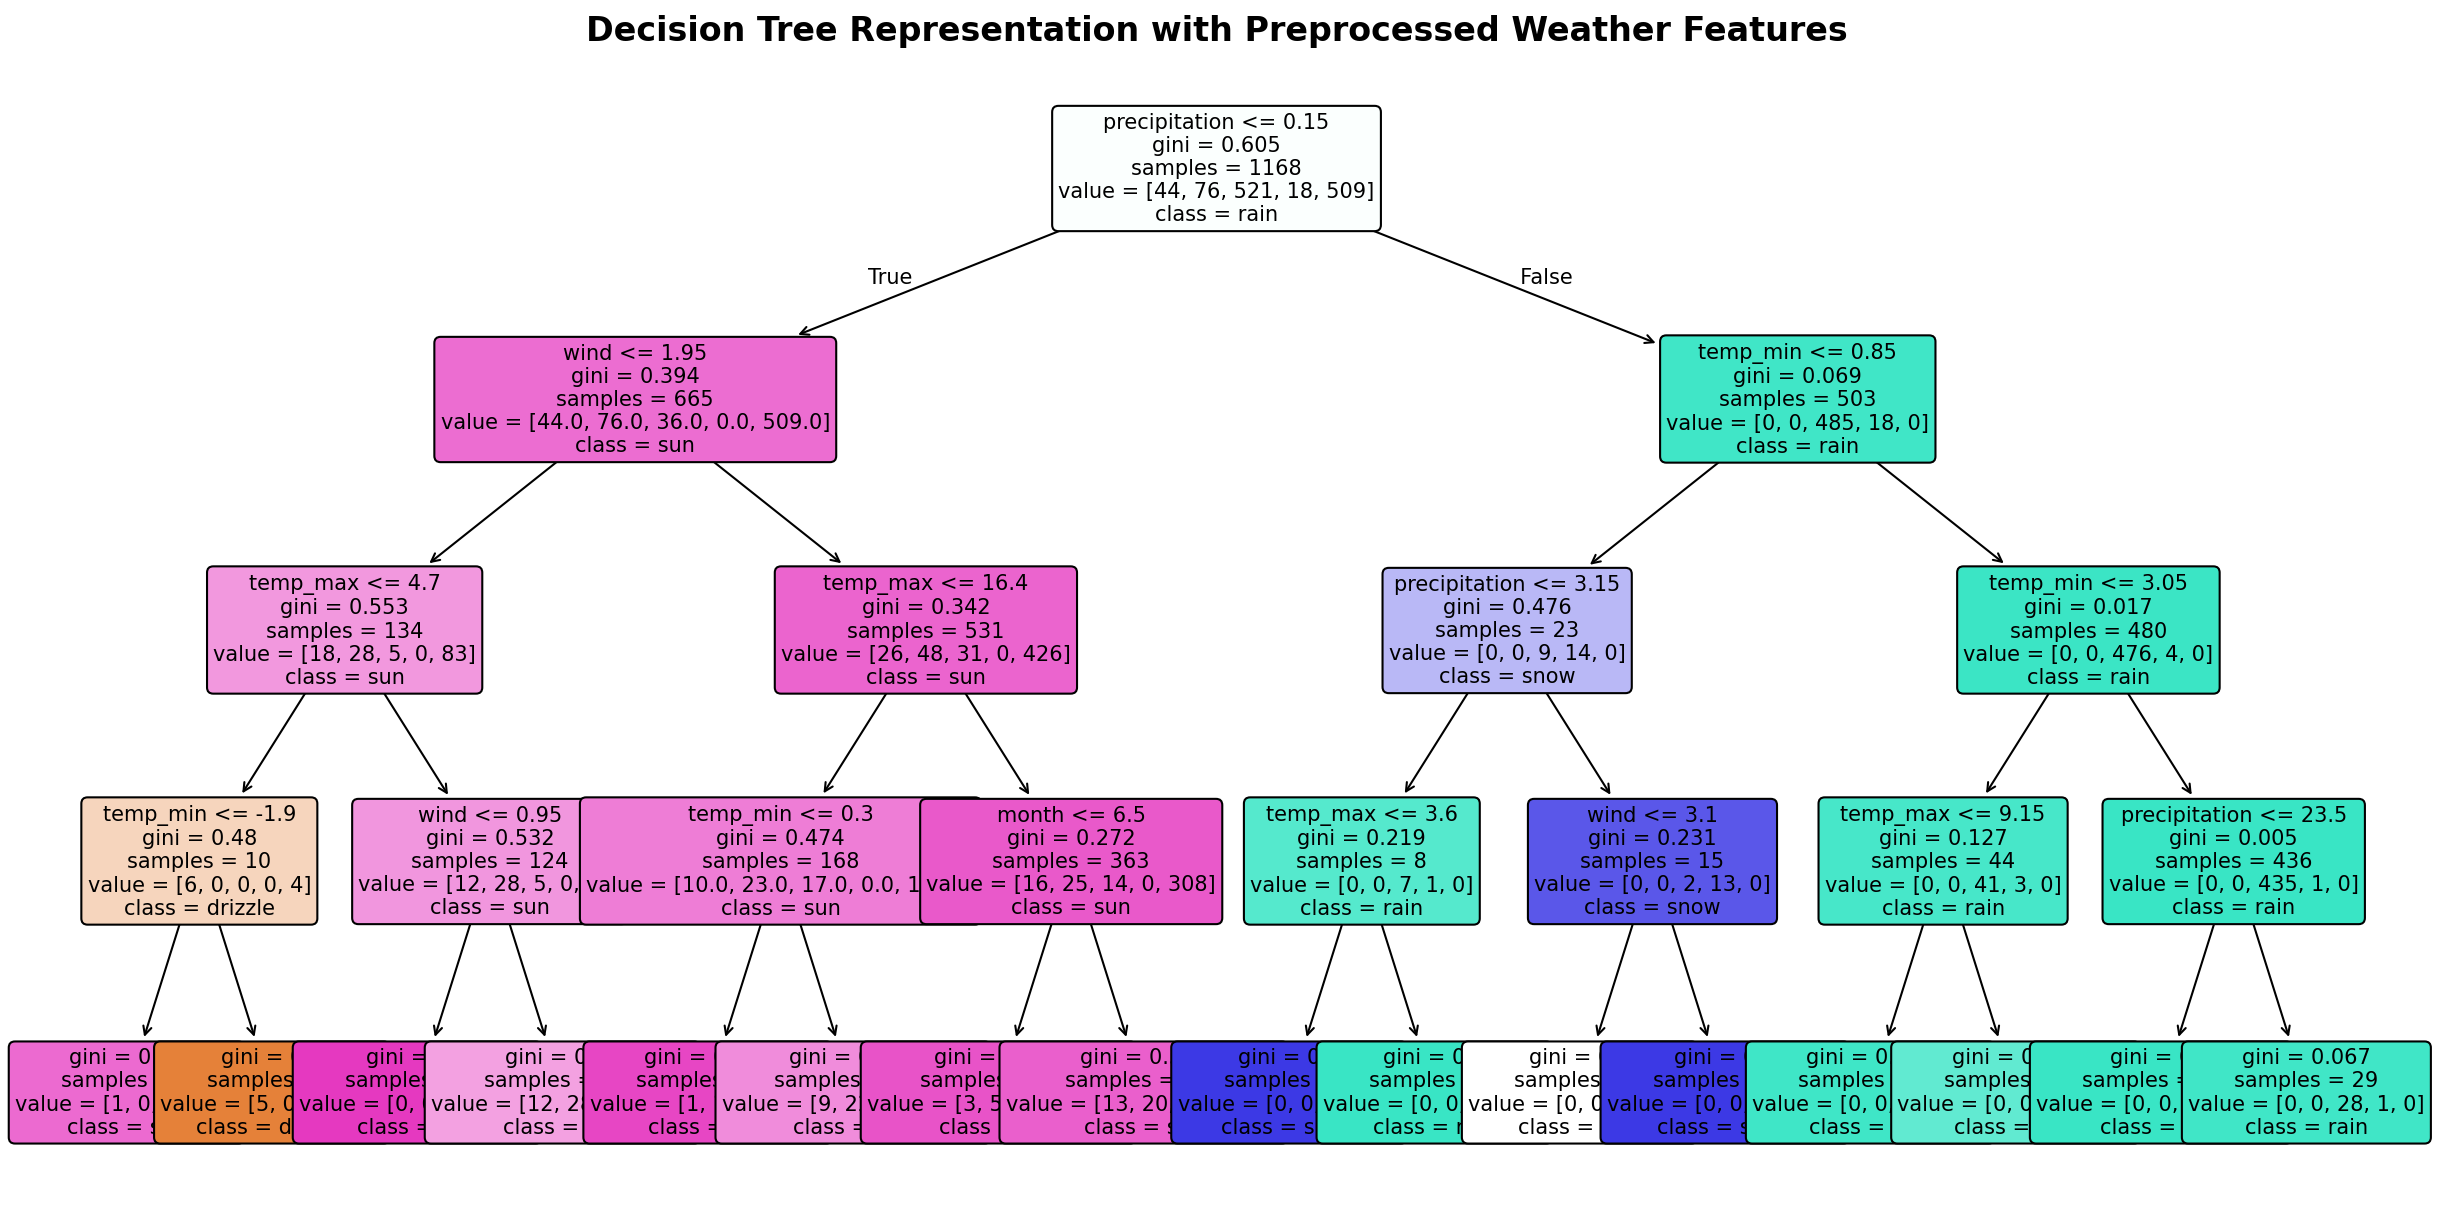

In [16]:
plt.figure(figsize=(20, 10), dpi=150)
plot_tree(
    dt_model,
    feature_names=list(X.columns),
    class_names=dt_model.classes_,
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title(
    'Decision Tree Representation with Preprocessed Weather Features',
    fontsize=16,
    fontweight='bold',
)
plt.show()